# Семинар 3. Фреймворки, критик, голосование и план: сколько стоит каждый

Третья неделя дала три лекции: фреймворки, Reflection и Self-Consistency, Planning. Сегодня собираем всё это руками на одном агенте и ведём **одну таблицу денег** через весь семинар. Каждая строка таблицы: сколько вызовов, сколько токенов, сколько центов и сколько верных ответов.

Главный прибор семинара это счётчик на уровне HTTP. Голый цикл, LangGraph и smolagents ходят в OpenRouter через один и тот же клиент, и мы видим каждый запрос: сколько сообщений, сколько инструментов, какой системный промпт подложила библиотека и во что это обошлось. Цену каждого вызова OpenRouter возвращает сам в поле `usage.cost`.

Тезис курса прежний: **хороший агент на дешёвой модели обходится дешевле сильной модели в одиночку при том же качестве.** Сегодняшний вопрос к нему: сколько из этой экономии съедает фреймворк и какой паттерн недели окупается.

Девять спринтов, десять дырок, ни одна не длиннее десяти строк. Пояснения к дыркам, хронометраж и домашка в `README.md`.

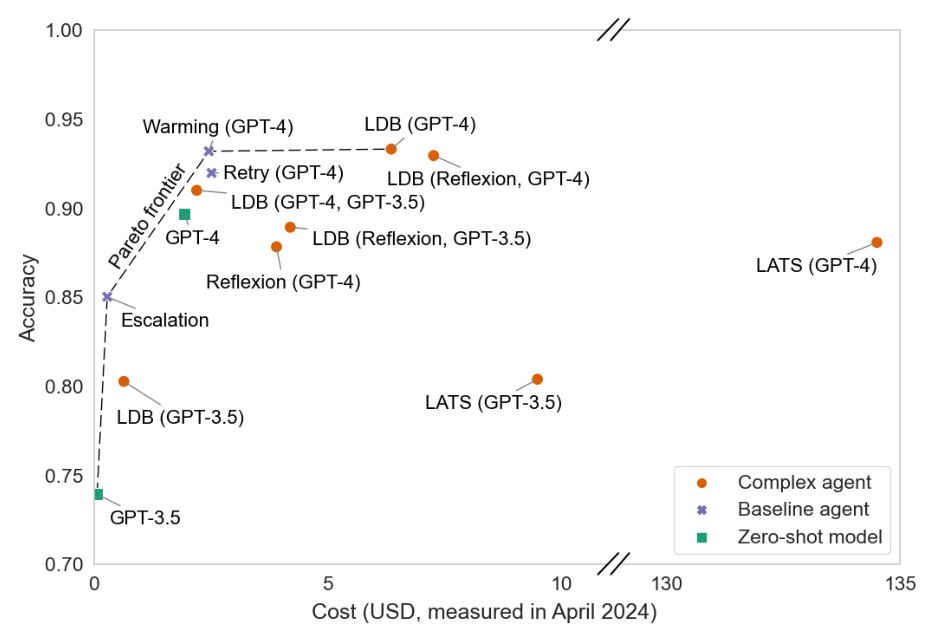

*Kapoor et al., 2024. AI Agents That Matter: точность против цены. Сложные агенты часто лежат правее простых базовых линий и не выше их. Сегодня строим такую картинку для своего агента*

## Шаг 1. Счётчик и базовая линия

**Ключ** OpenRouter: локально файл `.env` рядом с ноутбуком, в Kaggle секрет `OPENROUTER_API_KEY`. **Данные**: папка `data` рядом с ноутбуком. **Интернет**: агент ищет в Википедии, основная часть ответов лежит в снимке в `data`, остальное идёт в живую Википедию, в Kaggle включите Internet. Docker сегодня не нужен.

**Бюджет.** Полный прогон на сорока вопросах стоит порядка доллара, почти всё съедают строки с Sonnet. Если бюджет тесный, уменьшите `STRONG_SAMPLE`.

In [103]:
%pip install -q requests pydantic python-dotenv pandas matplotlib numpy httpx langgraph langchain langchain-openai smolagents

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [81]:
import os, re, json, gzip, time, warnings
os.environ.setdefault("LANGCHAIN_OPENAI_TCP_KEEPALIVE", "0")
warnings.filterwarnings("ignore")
from pathlib import Path
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from typing import TypedDict
import httpx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pydantic import BaseModel, Field

try:
    from dotenv import load_dotenv
    load_dotenv()
except ImportError:
    pass
try:
    from kaggle_secrets import UserSecretsClient
    os.environ.setdefault("OPENROUTER_API_KEY", UserSecretsClient().get_secret("OPENROUTER_API_KEY"))
except Exception:
    pass
KEY = os.getenv("OPENROUTER_API_KEY")
assert KEY, "нет ключа: положите его в .env рядом с ноутбуком или в Kaggle Secrets"

BASE_URL = "https://openrouter.ai/api/v1"
CHEAP, MID, STRONG = "openai/gpt-4o-mini", "anthropic/claude-haiku-4.5", "anthropic/claude-sonnet-4.6"
COLORS = {"violet": "#5436A3", "amber": "#F09000", "teal": "#00838F", "red": "#C43C3C", "grey": "#787882"}
DATA = next((p for p in [Path("data"), Path("/kaggle/input/seminar03-data"), Path("/kaggle/input/seminar03-data/data")]
             if (p / "fresh_2026.jsonl").exists()), Path("data"))
SAMPLE, STRONG_SAMPLE = 40, 40
Path("img").mkdir(exist_ok=True)

def load_jsonl(name):
    return [json.loads(line) for line in (DATA / name).read_text(encoding="utf-8").splitlines() if line.strip()]

def pmap(fn, items, workers=6):
    with ThreadPoolExecutor(workers) as ex:
        return list(ex.map(fn, items))

## Шаг 1.1 Счётчик: что на самом деле уходит в сеть

Все три исполнения агента, голый цикл, LangGraph и smolagents, внутри пользуются OpenAI-совместимым клиентом, а тот ходит в сеть через библиотеку `httpx`. Если дать им всем один и тот же `httpx.Client` с крючком на ответ, мы увидим каждый вызов модели, чей бы код его ни сделал. Никакой магии и никаких сторонних сервисов наблюдаемости: только то, что ушло в сеть и что пришло обратно.

Крючок получает ответ, у ответа есть исходный запрос. Из запроса берём модель, число сообщений и инструментов, из ответа поле `usage`: токены на входе, на выходе и цену. Каждый вызов помечаем текущей меткой `TAG`, чтобы потом сложить деньги по конфигурациям. Первый запрос под каждой меткой сохраняем целиком: по нему видно, какой системный промпт подложила библиотека.

Дырка: `on_response`. Чекпоинт: один вызов модели оставляет в `CALLS` строку с токенами и ценой.

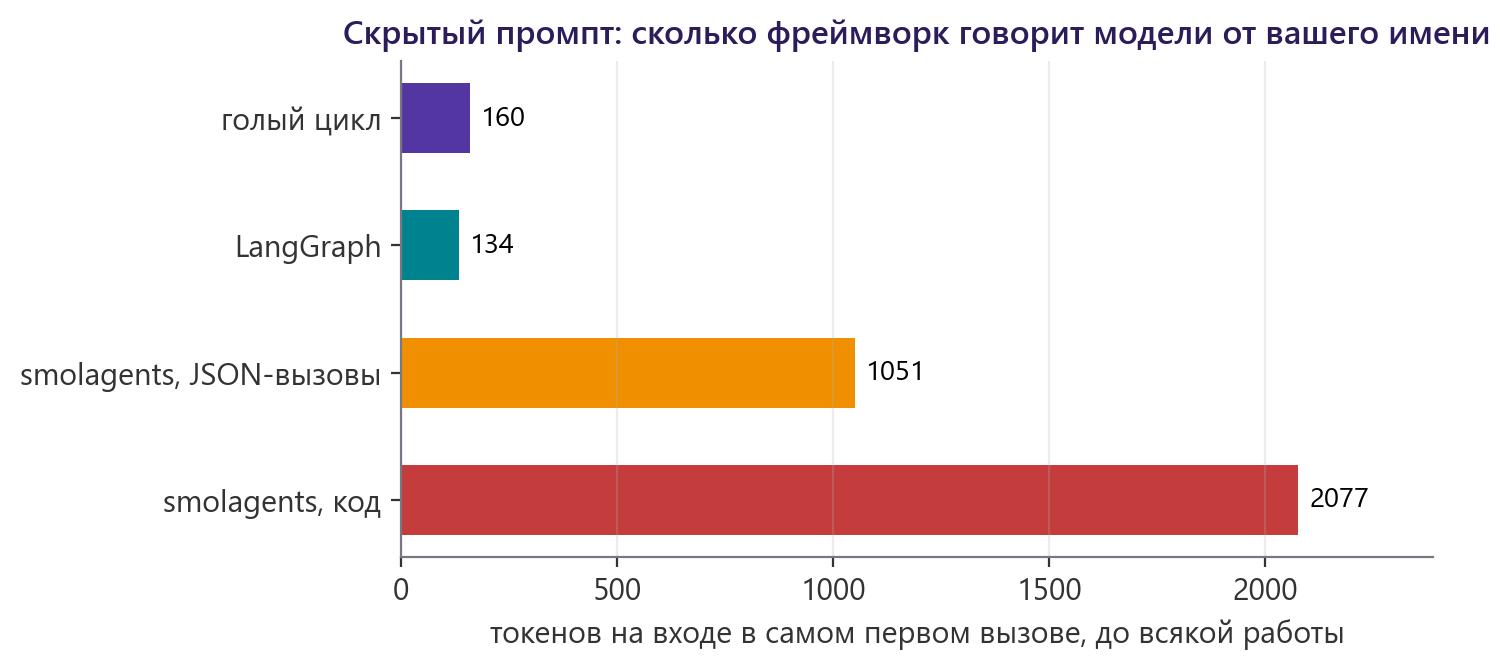

*Из седьмой лекции: сколько токенов уходит в первом же запросе у четырёх исполнений одного агента. Сегодня меряем то же самое своим счётчиком*

In [3]:
CALLS, FIRST, TAG = [], {}, {"now": "без метки"}

In [4]:
def on_response(response):
    response.read()
    request = json.loads(response.request.content or b"{}")
    usage = response.json().get("usage") or {}
    FIRST.setdefault(TAG["now"], request)
    CALLS.append({
        "tag":TAG["now"],
        "model": request.get("model", "?").split("/")[-1],
        "messages": len(request.get("messages", [])),
        "tools": len(request.get("tools", [])),
        "prompt": usage.get("prompt_tokens", 0),
        "completion": usage.get("completion_tokens", 0),
        "cost": usage.get("cost") or 0

    })



In [44]:
HTTP = httpx.Client(event_hooks={"response": [on_response]}, timeout=180)
HEADERS = {"Authorization": f"Bearer {KEY}", "X-Title": "agents-course-seminar03"}

def chat(messages, model=CHEAP, tools=None, temperature=0.0):
    body = {"model": model, "messages": messages, "temperature": temperature, "max_tokens": 1024}
    if tools:
        body["tools"] = tools
    for attempt in range(5):
        r = HTTP.post(f"{BASE_URL}/chat/completions", json=body, headers=HEADERS)
        if r.status_code == 200:
            return r.json()["choices"][0]["message"]
        time.sleep(2 * (attempt + 1))
    raise RuntimeError(f"HTTP {r.status_code}: {r.text[:200]}")

TAG["now"] = "проверка счётчика"
chat([{"role": "user", "content": "Say OK"}])
pd.DataFrame(CALLS)

,tag,model,messages,tools,prompt,completion,cost
0,проверка счётчика,gpt-4o-mini,1,0,9,2,0.000003
1,проба,gpt-4o-mini,2,2,184,26,0.000043
2,проба,gpt-4o-mini,4,2,454,28,0.000085
3,проба,gpt-4o-mini,6,2,496,26,0.000090
4,проба,gpt-4o-mini,8,2,785,29,0.000135
...,...,...,...,...,...,...,...
829,проверка счётчика,gpt-4o-mini,1,0,0,0,0.000000
830,проверка счётчика,gpt-4o-mini,1,0,0,0,0.000000
831,проверка счётчика,gpt-4o-mini,1,0,0,0,0.000000
832,проверка счётчика,gpt-4o-mini,1,0,0,0,0.000000


## Шаг 1.2. Инструменты и базовая линия

Агент тот же, что в первой домашке: свежие вопросы о событиях 2026 года и живая Википедия. Инструментов два, оба даны готовыми. `web_search` ищет статью и возвращает её вступление и ещё два заголовка. `page_find` заглядывает в полный текст статьи и возвращает строки с ключевыми словами.
Чекпоинт: строка «голый цикл, mini» в таблице и список неверных ответов.

In [11]:
tasks = load_jsonl("fresh_2026.jsonl")[:SAMPLE]
WIKI = "https://en.wikipedia.org/w/api.php"
WIKI_HEADERS = {"User-Agent": "agents-course-seminar03/1.0 (https://t.me/artemovma)"}
SNAPSHOT = DATA / "wiki_snapshot.json.gz"
WIKI_CACHE = json.loads(gzip.decompress(SNAPSHOT.read_bytes())) if SNAPSHOT.exists() else {}

def wiki(params):
    key = json.dumps(params, sort_keys=True)
    for attempt in range(4):
        if key not in WIKI_CACHE:
            try:
                r = httpx.get(WIKI, params={**params, "format": "json"}, headers=WIKI_HEADERS, timeout=25)
                r.raise_for_status()
                WIKI_CACHE[key] = r.json().get("query", {})
            except httpx.HTTPError as e:
                error = e
                time.sleep(2 * (attempt + 1))
                continue
        return WIKI_CACHE[key]
    raise RuntimeError(f"Википедия не отвечает: {error}")

def web_search(query: str) -> str:
    """Search English Wikipedia: returns the intro of the best article and the titles of two more articles."""
    hits = wiki({"action": "query", "list": "search", "srsearch": query, "srlimit": 3}).get("search", [])
    if not hits:
        return "nothing found"
    pages = wiki({"action": "query", "prop": "extracts", "explaintext": 1, "exintro": 1, "titles": hits[0]["title"]}).get("pages", {})
    intro = " ".join(next(iter(pages.values()), {}).get("extract", "").split())[:1200]
    return f"[{hits[0]['title']}] {intro} | other articles: " + ", ".join(h["title"] for h in hits[1:])

def page_find(title: str, keywords: str) -> str:
    """Look inside the full text of a Wikipedia article and return the lines that contain the keywords."""
    pages = wiki({"action": "query", "prop": "extracts", "explaintext": 1, "titles": title, "redirects": 1}).get("pages", {})
    text = next(iter(pages.values()), {}).get("extract", "")
    if not text:
        return "no such page"
    kws = [w for w in re.findall(r"\w+", keywords.lower()) if len(w) > 2]
    lines = [l.strip() for l in text.splitlines() if l.strip() and sum(w in l.lower() for w in kws) >= max(1, (len(kws) + 1) // 2)]
    return "\n".join(l[:350] for l in lines[:5]) or "keywords not found on the page"

len(tasks), sum(t["agent_ok"] for t in tasks), len(WIKI_CACHE), web_search("2026 Winter Paralympics")[:200], page_find("2026 in Ukraine", "Paralympics boycott")

(40,
 0,
 0,
 '[2026 Winter Paralympics] The 2026 Winter Paralympics (Italian: Giochi paralimpici invernali di Milano Cortina 2026), also known as the Milano Cortina 2026 Winter Paralympic Games, were the 14th editi',
 'Ukraine boycotts the opening ceremony of the 2026 Winter Paralympics in Italy in protest over Russian athletes being allowed to compete under the Russian flag after the lifting of sanctions imposed over the Russian invasion in 2022.\n15 March – Ukraine boycotts the closing ceremony of the 2026 Winter Paralympics in Italy in protest over Russian athletes being allowed to compete under the Russian flag after the lifting of sanctions imposed over the Russian invasion in 2022.')

In [7]:
AGENT_SYSTEM = ("You answer questions about events of 2026 using Wikipedia tools. Never answer from memory, do not repeat the same call. "
                "When done, reply with the short answer only, no explanation.")
BARE_TOOLS = [
    {"type": "function", "function": {"name": "web_search", "description": web_search.__doc__,
     "parameters": {"type": "object", "properties": {"query": {"type": "string", "description": "short query: a name, a title, an event"}}, "required": ["query"]}}},
    {"type": "function", "function": {"name": "page_find", "description": page_find.__doc__,
     "parameters": {"type": "object", "properties": {"title": {"type": "string", "description": "exact article title, e.g. 2026 in Japan"},
                                                     "keywords": {"type": "string", "description": "two to five keywords"}},
                    "required": ["title", "keywords"]}}}]
FUNCS = {"web_search": web_search, "page_find": page_find}
LAST_STEP = "No more tool calls. Answer now with what you found."

def bare_agent(question, model=CHEAP, max_steps=6):
    messages, seen = [{"role": "system", "content": AGENT_SYSTEM}, {"role": "user", "content": question}], set()
    for step in range(max_steps):
        last = step == max_steps - 1
        if last:
            messages.append({"role": "user", "content": LAST_STEP})
        msg = chat(messages, model, None if last else BARE_TOOLS)
        messages.append({k: v for k, v in msg.items() if k in ("role", "content", "tool_calls") and v})
        calls = msg.get("tool_calls") or []
        if not calls:
            return msg.get("content") or ""
        for c in calls:
            key = (c["function"]["name"], c["function"]["arguments"])
            result = "repeated call, answer now" if key in seen else FUNCS[key[0]](**json.loads(key[1]))
            seen.add(key)
            messages.append({"role": "tool", "tool_call_id": c["id"], "content": result})
    return messages[-1].get("content") or ""

In [12]:
NUMBERS = {w: str(n) for n, w in enumerate("zero one two three four five six seven eight nine ten eleven twelve".split())}

def norm(text):
    return " ".join(NUMBERS.get(w, w) for w in re.sub(r"\b(a|an|the)\b|[^\w\s]", " ", str(text).lower()).split())

def is_correct(task, answer):
    return set(norm(task["answer"]).split()) <= set(norm(answer).split())

RESULTS = {}

def run_config(tag, fn, sample=None, workers=6):
    sample = sample or tasks
    TAG["now"] = tag
    def one(task):
        try:
            return fn(task["question"])
        except Exception as e:
            return f"ошибка: {type(e).__name__}"
    answers = pmap(one, sample, workers)
    RESULTS[tag] = [{"id": t["id"], "answer": a, "ok": is_correct(t, a)} for t, a in zip(sample, answers)]
    return report([tag])

def report(tags=None):
    rows = []
    for tag in tags or RESULTS:
        res, calls = RESULTS[tag], [c for c in CALLS if c["tag"] == tag]
        n, ok, cost = len(res), sum(r["ok"] for r in res), sum(c["cost"] for c in calls)
        rows.append({"конфигурация": tag, "верно": f"{ok}/{n}", "доля": round(ok / n, 3), "вызовов на вопрос": round(len(calls) / n, 1),
                     "токенов на вопрос": round(sum(c["prompt"] + c["completion"] for c in calls) / n),
                     "центов на вопрос": round(cost / n * 100, 4), "центов за верный": round(cost / ok * 100, 4) if ok else None})
    return pd.DataFrame(rows)

def wrong(tag, n=10):
    return pd.DataFrame([{"эталон": t["answer"], "ответ": str(r["answer"])[:110]}
                         for t, r in zip(tasks, RESULTS[tag]) if not r["ok"]][:n])

TAG["now"] = "проба"
print(bare_agent(tasks[0]["question"]), "| эталон:", tasks[0]["answer"])
run_config("голый цикл, mini", bare_agent)

The doubly charmed baryon Ξcc⁺. | эталон: doubly charmed baryon Ξcc⁺


,конфигурация,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,"голый цикл, mini",20/40,0.5,8.7,4633,0.0777,0.1553


In [13]:
wrong("голый цикл, mini")

,эталон,ответ
0,"over 11,000",I could not find specific information about th...
1,Prototype Fast Breeder Reactor,The name of the 500 MWe reactor that attained ...
2,Gemini Enterprise Agent platform,I couldn't find specific information about the...
3,45,The information regarding the number of nearby...
4,GJ 887 d,The name of the super-Earth exoplanet discover...
5,AlphaGenome,I couldn't find the specific name of the AI mo...
6,Pinnacle Architecture,I couldn't find the specific name of the fault...
7,HD 137010 b,I couldn't find the name of the Earth-sized tr...
8,58 generations,The 20-year Japanese mouse cloning study found...
9,"252,757 miles (406,773 km)",The maximum distance from Earth reached by the...


## Шаг 2. LangGraph

В LangChain 1.x функция `create_agent` собирает тот же ReAct-цикл в виде графа LangGraph: узел модели, узел инструментов, ребро «есть вызовы инструментов, иди выполнять». Инструменты описываются декоратором `tool`: имя, схема из подсказок типов, описание из докстринга. Наши функции уже снабжены докстрингами, поэтому обёртка в одну строку. Или так кажется: проверим счётчиком.

Модель подключаем через `ChatOpenAI` с адресом OpenRouter и **нашим** клиентом `http_client=HTTP`: так каждый вызов LangGraph попадает в счётчик.

Дырка: `run_langgraph`. Собрать агента с моделью, инструментами, системным промптом и промежуточными слоями из списка `LG_MIDDLEWARE` (пока он пустой), вызвать на вопросе с лимитом рекурсии и вернуть весь список сообщений: в нём и ответ, и то, что вернули инструменты, это понадобится критику. `ask_langgraph` рядом берёт из списка только текст ответа. Параметры `temperature` и `extra` понадобятся во второй половине семинара: для голосования и для плана в системном промпте.

Чекпоинт: строка «LangGraph как есть, mini» и список её неверных ответов.

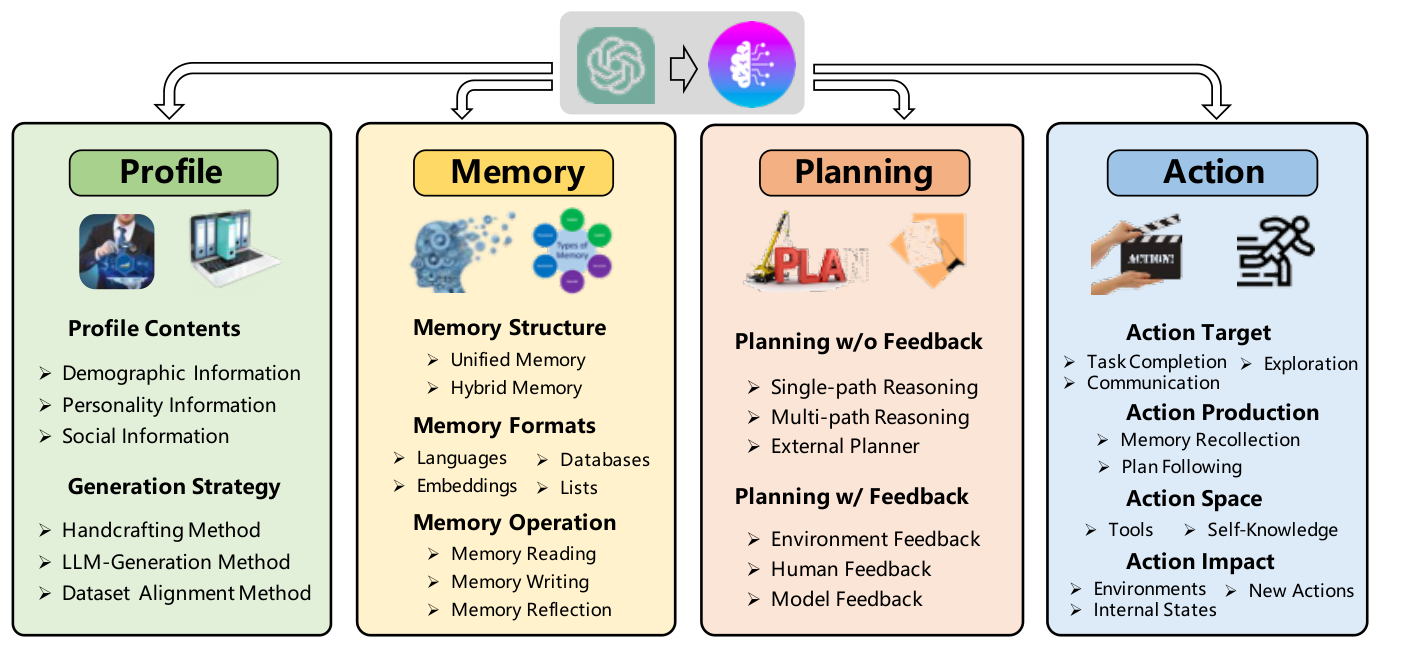

*Wang et al., 2023. Устройство агента в четырёх модулях. Фреймворк не добавляет пятого модуля, он даёт готовую проводку между этими четырьмя*

In [85]:
from langchain_openai import ChatOpenAI
from langchain.agents import create_agent
from langchain_core.tools import tool

LC_TOOLS = [tool(web_search), tool(page_find)]
LG_MIDDLEWARE = []
def lc_model(model=CHEAP, temperature=0.0):
    max_tokens = 1024
    return ChatOpenAI(model=model, base_url=BASE_URL, api_key=KEY, http_client=HTTP, temperature=temperature, max_tokens=max_tokens) #!

In [86]:
def run_langgraph(question, model=CHEAP, temperature=0.0, extra=""):
    agent = create_agent(lc_model(model, temperature), tools=LC_TOOLS, system_prompt=AGENT_SYSTEM + extra, middleware=LG_MIDDLEWARE)
    out = agent.invoke(
        {"messages": [{"role": "user", "content": question}]},
        {"recursion_limit": 14}
    )
    return out["messages"]


### Проанализируем просто запрос агента на реквестах и агента на лангграфе

In [21]:
question = "Сколько будет 2 + 2? Ответь одним числом."
TAG["now"] = "bare|empty"
bare_agent(question)
bare_first = FIRST["bare|empty"]
bare_rec = [c for c in CALLS if c['tag'] == TAG["now"]][0]

TAG["now"] = "langgraph|empty"
run_langgraph(question)
lg_first = FIRST["langgraph|empty"]
lg_rec   = [c for c in CALLS if c['tag'] == TAG["now"]][0]

In [22]:
bare_first

{'model': 'openai/gpt-4o-mini',
 'messages': [{'role': 'system',
   'content': 'You answer questions about events of 2026 using Wikipedia tools. Never answer from memory, do not repeat the same call. When done, reply with the short answer only, no explanation.'},
  {'role': 'user', 'content': 'Сколько будет 2 + 2? Ответь одним числом.'}],
 'temperature': 0.0,
 'tools': [{'type': 'function',
   'function': {'name': 'web_search',
    'description': 'Search English Wikipedia: returns the intro of the best article and the titles of two more articles.',
    'parameters': {'type': 'object',
     'properties': {'query': {'type': 'string',
       'description': 'short query: a name, a title, an event'}},
     'required': ['query']}}},
  {'type': 'function',
   'function': {'name': 'page_find',
    'description': 'Look inside the full text of a Wikipedia article and return the lines that contain the keywords.',
    'parameters': {'type': 'object',
     'properties': {'title': {'type': 'string',

In [23]:
lg_first

{'messages': [{'content': 'You answer questions about events of 2026 using Wikipedia tools. Never answer from memory, do not repeat the same call. When done, reply with the short answer only, no explanation.',
   'role': 'system'},
  {'content': 'Сколько будет 2 + 2? Ответь одним числом.', 'role': 'user'}],
 'model': 'openai/gpt-4o-mini',
 'stream': False,
 'temperature': 0.0,
 'tools': [{'type': 'function',
   'function': {'name': 'web_search',
    'description': 'Search English Wikipedia: returns the intro of the best article and the titles of two more articles.',
    'parameters': {'properties': {'query': {'type': 'string'}},
     'required': ['query'],
     'type': 'object'}}},
  {'type': 'function',
   'function': {'name': 'page_find',
    'description': 'Look inside the full text of a Wikipedia article and return the lines that contain the keywords.',
    'parameters': {'properties': {'title': {'type': 'string'},
      'keywords': {'type': 'string'}},
     'required': ['title', '

In [24]:
bare_rec

{'tag': 'bare|empty',
 'model': 'gpt-4o-mini',
 'messages': 2,
 'tools': 2,
 'prompt': 177,
 'completion': 2,
 'cost': 2.775e-05}

In [25]:
lg_rec

{'tag': 'langgraph|empty',
 'model': 'gpt-4o-mini',
 'messages': 2,
 'tools': 2,
 'prompt': 145,
 'completion': 2,
 'cost': 2.295e-05}

**Результат:** В данном случае промт с langgraph меньше, но это из-за того, что он удалил description в описании тулов, а еще добавил параметр  'stream': False

### Прогоним наш датасет на langgraph агенте

In [87]:
def ask_langgraph(question, model=CHEAP, temperature=0.0, extra=""):
    return run_langgraph(question, model, temperature, extra)[-1].content

In [88]:
from langchain.agents.middleware import wrap_model_call
from langchain_core.messages import HumanMessage

class SearchArgs(BaseModel):
    query: str = Field(description="short query: a name, a title, an event")

class FindArgs(BaseModel):
    title: str = Field(description="exact article title, e.g. 2026 in Japan")
    keywords: str = Field(description="two to five keywords")

LC_TOOLS = [tool(web_search, args_schema=SearchArgs), tool(page_find, args_schema=FindArgs)]

In [89]:
@wrap_model_call
def last_step_without_tools(request, handler):
    if sum(m.type == 'ai' for m in request.messages) >= 5:
        request = request.override(tools=[], messages=request.messages + [HumanMessage(LAST_STEP)])
    return handler(request)
    


In [91]:
LG_MIDDLEWARE.append(last_step_without_tools)
run_config("LangGraph, mini", ask_langgraph)
report(["голый цикл, mini", "LangGraph, mini"])

,конфигурация,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,"голый цикл, mini",20/40,0.5,8.7,4633,0.0777,0.1553
1,"LangGraph, mini",20/40,0.5,3.7,1944,0.0325,0.0650


### Дорогая модель без инсрументов

In [37]:
BASELINE_SYSTEM = "You answer questions about events of 2026. Reply with the short answer only, no explanation."

def ask_baseline(question, model=STRONG, temperature=0.0):
    msgs = [
        {"role": "system", "content": BASELINE_SYSTEM},
        {"role": "user",   "content": question},
    ]
    msg = chat(msgs, model, None)
    return msg.get("content") or ""

TAG["now"] = "sonnet, no tools"
run_config("sonnet, no tools", ask_baseline)
report(["голый цикл, mini", "LangGraph, mini", "sonnet, no tools"])

,конфигурация,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,"голый цикл, mini",20/40,0.5,8.7,4633,0.0777,0.1553
1,"LangGraph, mini",20/40,0.5,3.7,1944,0.0325,0.0650
2,"sonnet, no tools",4/40,0.1,1.9,81,0.0664,0.6642


## Шаг 3. Два паттерна недели

### Шаг 3.1 Критик графом: LangGraph как явная схема

До сих пор LangGraph был для нас готовым циклом. Его сила в другом: в явном графе, где вы сами решаете, какие узлы есть и куда ведут рёбра. Соберём граф из восьмой лекции: агент отвечает, критик проверяет, при отказе агент получает замечание и ищет заново, но не больше двух попыток.

Критик сделан по уроку восьмой лекции: он не мнение той же модели о своём ответе, а **проверка с опорой**. Узел агента сохраняет в состоянии всё, что вернули инструменты за прогон, а критик сверяет ответ с этими находками. Так ловится главная болезнь агента с поиском: поиск ничего не дал, и модель ответила по памяти. Вердикт приходит не текстом, а объектом Pydantic через `with_structured_output`: так ответ критика не надо разбирать регулярками.

Две дырки. `critic_node`: спросить модель по схеме `Verdict`, показав вопрос, ответ и находки агента, вернуть замечание (пустое, если ответ подтверждён) и увеличенный счётчик проверок. `route`: вернуться к агенту, если есть замечание и попыток было меньше двух, иначе закончить.

Чекпоинт: строка «LangGraph + критик» и счёт «исправил против испортил» относительно LangGraph без критика.

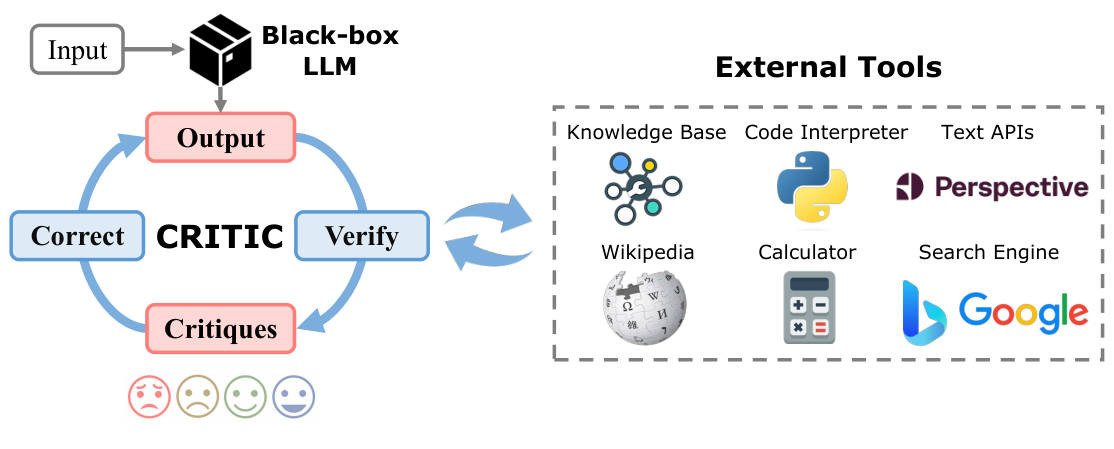

*Gou et al., 2023. CRITIC: проверка ответа с помощью инструментов, а не самооценкой. Так же устроен наш критик*

In [52]:
from langgraph.graph import StateGraph, START, END

class QA(TypedDict):
    question: str
    answer: str
    evidence: str
    feedback: str
    rounds: int
    checks: int

class Verdict(BaseModel):
    supported: bool = Field(description="true only if the evidence explicitly supports the answer")
    issue: str = Field(description="what is wrong or missing, empty if supported")

CRITIC_SYSTEM = ("You check a short answer against the evidence the agent retrieved from Wikipedia. Judge only by the evidence. "
                 "If the evidence does not contain the answer, the answer is not supported.")

def answer_node(state):
    note = ""
    if state["feedback"]:
        note = f"\n\nA reviewer rejected your previous answer '{state['answer']}': {state['feedback']} Search again and correct it."
    messages = run_langgraph(state["question"] + note)
    found = "\n".join(str(m.content)[:800] for m in messages if m.type == "tool")
    return {"answer": messages[-1].content, "evidence": found[-4000:], "rounds": state["rounds"] + 1}

In [53]:
def critic_node(state):
    judge = lc_model(CHEAP).with_structured_output(Verdict)
    verdict = judge.invoke([
        ("system", CRITIC_SYSTEM),
        ("user", f"Question: {state['question']}\nAnswer: {state['answer']}\n"
                 f"Evidence the agent found:\n{state['evidence'] or 'nothing'}")
    ])
    return {"feedback": "" if verdict.supported else verdict.issue, "checks": state["checks"] + 1}


In [54]:
def route(state):
    if state["feedback"] and state["rounds"] < 2:
        return 'answer'
    return END


In [55]:
graph = StateGraph(QA)
graph.add_node("answer", answer_node)
graph.add_node("critic", critic_node)
graph.add_edge(START, "answer")
graph.add_edge("answer", "critic")
graph.add_conditional_edges("critic", route, ["answer", END])
checked = graph.compile()
print(checked.get_graph().draw_mermaid())

def ask_checked(question):
    return checked.invoke({"question": question, "answer": "", "evidence": "", "feedback": "", "rounds": 0, "checks": 0})["answer"]

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	answer(answer)
	critic(critic)
	__end__([<p>__end__</p>]):::last
	__start__ --> answer;
	answer --> critic;
	critic -.-> __end__;
	critic -.-> answer;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



In [56]:
ask_checked("Who is Albert Einstein?")

'Albert Einstein (14 March 1879 – 18 April 1955) was a German-born theoretical physicist best known for developing the theory of relativity.'

In [58]:
run_config("LangGraph критик, mini", ask_checked)
base, crit = RESULTS["LangGraph, mini"], RESULTS["LangGraph критик, mini"]
fixed = sum(not b["ok"] and c["ok"] for b, c in zip(base, crit))
broken = sum(b["ok"] and not c["ok"] for b, c in zip(base, crit))
print("исправил", fixed, "| испортил", broken)
report(["голый цикл, mini", "LangGraph, mini", "sonnet, no tools", "LangGraph критик, mini"])

исправил 3 | испортил 4


,конфигурация,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,"голый цикл, mini",20/40,0.500,8.7,4633,0.0777,0.1553
1,"LangGraph, mini",20/40,0.500,3.7,1944,0.0325,0.0650
2,"sonnet, no tools",4/40,0.100,1.9,81,0.0664,0.6642
3,"LangGraph критик, mini",19/40,0.475,5.8,4004,0.0604,0.1272


## ШАГ 3.2 Голосование и каскад по согласию

Восьмая лекция: независимые голоса лечат случайные ошибки, а их согласие это уверенность, которой можно верить. Здесь каждый голос это целый прогон агента с поиском при температуре 0.7, три голоса идут параллельно. Ответы агента пишутся по-разному: «15 March» и «March 15», поэтому сравниваем их как набор слов после нормализации.

Каскад: если все три голоса дешёвой модели совпали, берём ответ. Если нет, задача уходит тому же агенту на Sonnet. Для сравнения тут же строка «LangGraph, Sonnet»: сильная модель на всех вопросах подряд.

Две дырки. `vote`: запустить `k` прогонов параллельно, найти самый частый ответ и вернуть его вместе с долей согласных. `cascade`: три голоса, при полном согласии их ответ, иначе Sonnet.

Чекпоинт: три строки в таблице и число задач, ушедших наверх.

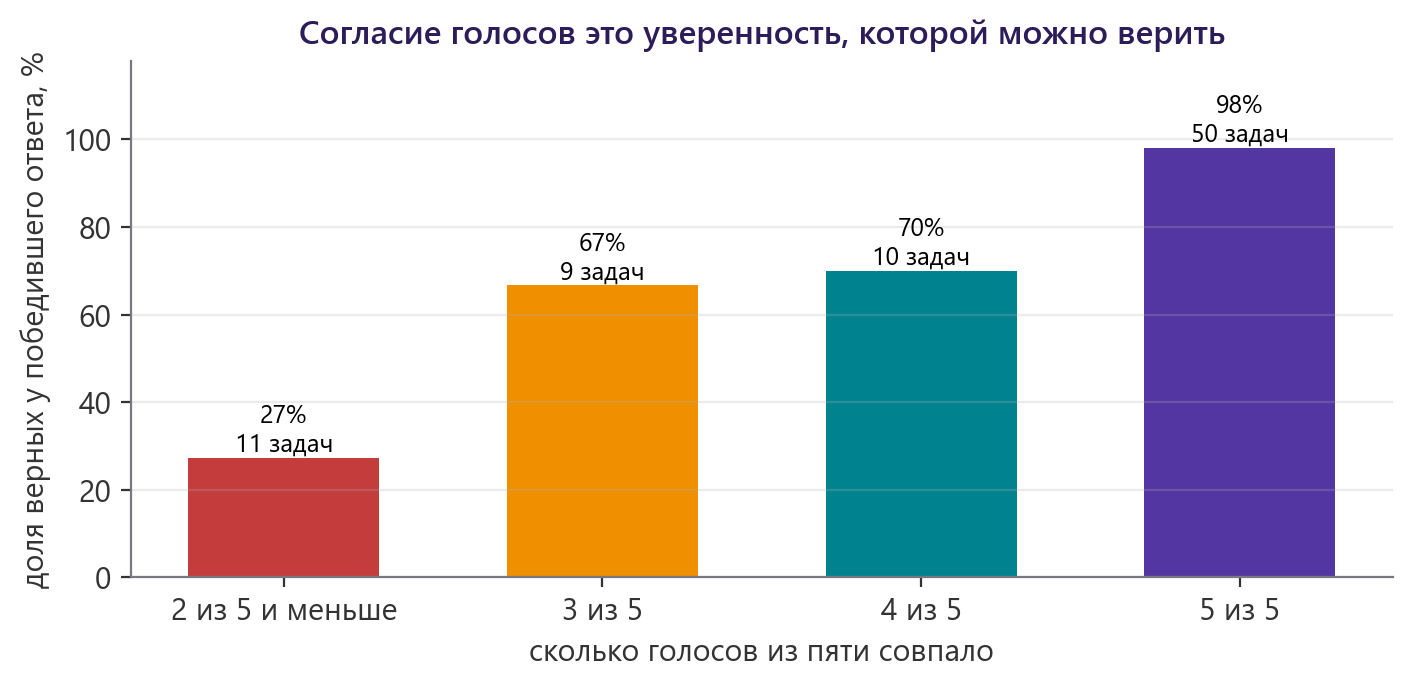

*Из восьмой лекции: когда все пять голосов совпали, ответ верен в 49 случаях из 50. При разногласии верность падает до монетки*

In [92]:
def bag(answer):
    return " ".join(sorted(norm(answer).split()))

In [93]:
def vote(question, k=3):
    with ThreadPoolExecutor(k) as ex:
        answers = list(ex.map(lambda _: ask_langgraph(question, CHEAP, 0.7), range(k)))
    keys = [bag(a) for a in answers]
    top, n = Counter(keys).most_common(1)[0]
    return {"answer": answers[keys.index(top)], "agreement": n / k}


In [94]:
def cascade(question):
    v = vote(question, 3)
    if v["agreement"] == 1:
        return v["answer"]
    ESCALATED.append(question)
    return ask_langgraph(question, STRONG)
    


In [95]:
cascade("Who is Albert Einstein?")

"I'm sorry, but I can only answer questions about **events of 2026** using my available Wikipedia tools. Albert Einstein is a historical figure, and questions about him fall outside the scope of what I'm able to help with here.\n\nIf you have any questions about **2026 events** — such as sports, politics, science, or culture — feel free to ask! 😊"

## Шаг 4. ИТОГ

In [97]:
ESCALATED = []
run_config("голосование 3, mini gpt", lambda q: vote(q, 3)["answer"])
run_config("каскад: 3 голоса mini gpt, иначе Sonnet", cascade)
print("ушло наверх:", len(ESCALATED), "из", len(tasks))
report(["голый цикл, mini", "LangGraph, mini", "sonnet, no tools", 
        "LangGraph критик, mini", "голосование 3, mini gpt", "каскад: 3 голоса mini gpt, иначе Sonnet"])

ушло наверх: 36 из 40


,конфигурация,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,"голый цикл, mini",20/40,0.500,8.7,4633,0.0777,0.1553
1,"LangGraph, mini",20/40,0.500,3.7,1944,0.0325,0.0650
2,"sonnet, no tools",4/40,0.100,1.9,81,0.0664,0.6642
3,"LangGraph критик, mini",19/40,0.475,5.8,4004,0.0604,0.1272
4,"голосование 3, mini gpt",22/40,0.550,12.2,7261,0.1222,0.2221
5,"каскад: 3 голоса mini gpt, иначе Sonnet",7/40,0.175,14.7,8391,0.2979,1.7021


## Шаг 5. Ограничение на бюджет

Две вещи, ради которых фреймворк правда стоит своих токенов. Первая: **остановка на подтверждение**. Агенту дают необратимый инструмент, отправку письма. Промежуточный слой `HumanInTheLoopMiddleware` останавливает граф перед вызовом, состояние сохраняется в чекпоинтере, человек решает: одобрить, поправить или отказать с комментарием. Потом граф продолжает с того же места. Руками это десятки строк и своё хранилище состояний.

Вторая: **бюджет**. `ModelCallLimitMiddleware` обрывает прогон после заданного числа вызовов модели. Это не заменяет лимит шагов в цикле, а ставит потолок на деньги сверху, на уровне фреймворка.

Здесь дырок нет, ячейки готовые. Чекпоинт: прерывание с ожидающим вызовом, отказ с комментарием, одобрение и обрыв по бюджету.

In [103]:
from langchain.agents.middleware import HumanInTheLoopMiddleware, ModelCallLimitMiddleware

In [104]:
def run_langgraph(question, model=CHEAP, temperature=0.0, extra=""):
    agent = create_agent(lc_model(model, temperature), tools=LC_TOOLS, system_prompt=AGENT_SYSTEM + extra, middleware=[ModelCallLimitMiddleware(run_limit=2, exit_behavior="end")])
    out = agent.invoke(
        {"messages": [{"role": "user", "content": question}]},
        {"recursion_limit": 14}
    )
    return out["messages"]

In [141]:
TAG["now"] = "бюджет"
capped = create_agent(lc_model(CHEAP), tools=LC_TOOLS, system_prompt=AGENT_SYSTEM,
                      middleware=[ModelCallLimitMiddleware(run_limit=2, exit_behavior="end")])
out = capped.invoke({"messages": [{"role": "user", "content": "Compare the months of the 2026 Winter Olympics and the 2026 FIFA World Cup, then list three events of each."}]})
print(out["messages"][-1].content[:300])
print("вызовов модели:", sum(c["tag"] == "бюджет" for c in CALLS))

Model call limits exceeded: run limit (2/2)
вызовов модели: 2


In [105]:
run_config("LangGraph, mini_бюджет", ask_langgraph)

,конфигурация,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,"LangGraph, mini_бюджет",7/40,0.175,2.0,628,0.0118,0.0674


In [106]:
wrong("LangGraph, mini_бюджет")

,эталон,ответ
0,doubly charmed baryon Ξcc⁺,Model call limits exceeded: run limit (2/2)
1,Antimatter particles,Model call limits exceeded: run limit (2/2)
2,"over 11,000",Model call limits exceeded: run limit (2/2)
3,Prototype Fast Breeder Reactor,Model call limits exceeded: run limit (2/2)
4,Microsoft CEO Satya Nadella,Model call limits exceeded: run limit (2/2)
5,Gemini Enterprise Agent platform,Model call limits exceeded: run limit (2/2)
6,lab-grown oesophagus,Model call limits exceeded: run limit (2/2)
7,45,Model call limits exceeded: run limit (2/2)
8,GJ 887 d,Model call limits exceeded: run limit (2/2)
9,AlphaGenome,Model call limits exceeded: run limit (2/2)
